# Amazon Review Summarization Pipeline
### Corrected & extended — local LLM inference (no API key required)

**Pipeline stages:**
1. Dataset loading (JSONL)
2. Review preprocessing
3. Sentence extraction
4. Sentence embeddings (`all-MiniLM-L6-v2`)
5. Dimensionality reduction — UMAP for **visualization only**
6. Theme discovery — HDBSCAN on **full embeddings**
7. *(New)* Per-cluster sentiment polarity — computed **before** contrastive ranking
8. Contrastive theme ranking — uses polarity score, not frequency
9. Aspect-based theme **labelling** — keyword vote post-hoc (no second clustering pass)
10. Helpfulness & temporal weighting
11. Opinion diversity filtering
12. Local LLM synthesis — `flan-t5-large` / `bart-large-cnn` / `Mistral-7B` (your choice)
13. Visualization & evaluation

> **Corrections applied vs original pipeline:**
> - UMAP moved to visualization-only (Stage 5); HDBSCAN receives full 384-dim embeddings
> - Per-cluster sentiment polarity inserted as new Stage 7, before contrastive ranking
> - Hierarchical re-clustering (original Stage 9) removed; replaced by keyword-vote labelling
> - Anthropic API replaced entirely by local HuggingFace model inference


## 0 · Installation

In [ ]:
# Core pipeline dependencies
# GPU users: replace 'cpu' with 'cu118' or 'cu121' in the torch index URL
%pip install -q torch --index-url https://download.pytorch.org/whl/cpu
%pip install -q transformers sentence-transformers datasets
%pip install -q hdbscan umap-learn scikit-learn matplotlib tqdm
# Optional — only needed for Mistral 4-bit quantization on GPU
# %pip install -q bitsandbytes accelerate

In [ ]:
# Download the real Amazon Reviews 2023 dataset from HuggingFace
from datasets import load_dataset
import json

CATEGORY = "Electronics"      # change to Books, Sports, etc.
KEYWORD  = "headphones"       # optional filter — set to "" for all
OUTPUT   = "Electronics.jsonl"
MAX      = 2000

print(f"Streaming {CATEGORY} reviews from HuggingFace...")
ds = load_dataset(
    "McAuley-Lab/Amazon-Reviews-2023",
    f"raw_review_{CATEGORY}",
    split="full",
    streaming=True,
    trust_remote_code=True,
)

written = 0
with open(OUTPUT, "w") as f:
    for row in ds:
        if written >= MAX:
            break
        text = row.get("text", "") or ""
        if KEYWORD and KEYWORD.lower() not in text.lower():
            continue
        record = {
            "reviewText":  text,
            "overall":     row.get("rating", 3),
            "summary":     row.get("title", ""),
            "helpful":     [row.get("helpful_vote", 0), 0],
            "reviewTime":  "01 1, 2023",
            "verified":    row.get("verified_purchase", False),
        }
        f.write(json.dumps(record) + "\n")
        written += 1

print(f"Saved {written} reviews to '{OUTPUT}'")

`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'McAuley-Lab/Amazon-Reviews-2023' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.
ERROR:datasets.load:`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'McAuley-Lab/Amazon-Reviews-2023' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.


Streaming Electronics reviews from HuggingFace...


README.md: 0.00B [00:00, ?B/s]

Amazon-Reviews-2023.py: 0.00B [00:00, ?B/s]

RuntimeError: Dataset scripts are no longer supported, but found Amazon-Reviews-2023.py

## 1 · Imports & configuration

In [ ]:
import json, re, os, math
from pathlib import Path
from collections import defaultdict, Counter
from datetime import datetime
from typing import Optional

import torch
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from tqdm import tqdm

# ── User-configurable settings ────────────────────────────────────────────────
DATA_PATH        = "Electronics.jsonl"   # path to your Amazon JSONL file
MAX_REVIEWS      = 2000                  # cap for faster iteration
KEYWORD_FILTER   = "headphones"          # optional keyword filter (or "" for none)

# Model selection — pick one:
#   "flan-t5-base"       250 MB  CPU-friendly, fastest
#   "flan-t5-large"      780 MB  best CPU trade-off  ← default
#   "bart-large-cnn"     1.6 GB  news-summarization tuned
#   "flan-t5-xl"         3   GB  stronger, needs GPU
#   "mistral-7b-instruct" 14 GB  best quality, 4-bit GPU
SELECTED_MODEL   = "flan-t5-large"

HDBSCAN_MIN_SIZE = 25                    # min sentences per cluster
TOP_N_THEMES     = 8                     # themes passed to LLM
SENTENCES_PER_BUCKET = 2                 # pos/neu/neg sentences per theme→LLM

print("Config loaded.")
print(f"  Data path : {DATA_PATH}")
print(f"  Model     : {SELECTED_MODEL}")
print(f"  Device    : {'cuda' if torch.cuda.is_available() else 'cpu'}")


Config loaded.
  Data path : Electronics.jsonl
  Model     : flan-t5-large
  Device    : cuda


## 2 · Model registry

In [ ]:
MODEL_REGISTRY = {
    "flan-t5-base": {
        "hf_id":         "google/flan-t5-base",
        "type":          "seq2seq",
        "size_mb":       250,
        "max_input":     512,
        "max_new_tokens":200,
        "device":        "cpu",
    },
    "flan-t5-large": {
        "hf_id":         "google/flan-t5-large",
        "type":          "seq2seq",
        "size_mb":       780,
        "max_input":     512,
        "max_new_tokens":300,
        "device":        "cpu",
    },
    "flan-t5-xl": {
        "hf_id":         "google/flan-t5-xl",
        "type":          "seq2seq",
        "size_mb":       3072,
        "max_input":     512,
        "max_new_tokens":300,
        "device":        "cuda" if torch.cuda.is_available() else "cpu",
    },
    "bart-large-cnn": {
        "hf_id":         "facebook/bart-large-cnn",
        "type":          "seq2seq",
        "size_mb":       1600,
        "max_input":     1024,
        "max_new_tokens":256,
        "device":        "cpu",
    },
    "mistral-7b-instruct": {
        "hf_id":         "mistralai/Mistral-7B-Instruct-v0.3",
        "type":          "causal",
        "size_mb":       14336,
        "max_input":     4096,
        "max_new_tokens":512,
        "device":        "cuda",   # requires GPU + bitsandbytes
    },
}

cfg = MODEL_REGISTRY[SELECTED_MODEL]
print(f"Selected model : {cfg['hf_id']}")
print(f"Type           : {cfg['type']}")
print(f"Size           : {cfg['size_mb']:,} MB")
print(f"Inference on   : {cfg['device']}")


Selected model : google/flan-t5-large
Type           : seq2seq
Size           : 780 MB
Inference on   : cpu


## Stage 1 · Dataset loading (JSONL)

Expected JSONL schema (Amazon review format):
```json
{"reviewText": "...", "overall": 5.0, "summary": "Great!", "helpful": [4, 5],
 "reviewTime": "12 15, 2023", "verified": true}
```

**Public datasets you can use:**
- [McAuley-Lab/Amazon-Reviews-2023](https://huggingface.co/datasets/McAuley-Lab/Amazon-Reviews-2023) — download via HuggingFace
- [Julian McAuley's legacy datasets](https://cseweb.ucsd.edu/~jmcauley/datasets/amazon_v2/) — direct JSONL download

If `DATA_PATH` does not exist, the cell auto-generates synthetic demo data so you can run the full pipeline immediately.


In [ ]:
def generate_demo_data(n: int = 120) -> list[dict]:
    """Synthetic demo reviews — covers all pipeline stages without a real dataset."""
    import random, string
    random.seed(42)
    aspects = {
        "sound quality":     (4.4, ["The audio clarity is outstanding.", "Bass response is deep and punchy.",
                                     "Treble sounds a bit harsh at high volumes.", "Crystal-clear highs and mids."]),
        "battery life":      (3.6, ["Battery easily lasts 28 hours.", "Charge drains faster with ANC on.",
                                     "Battery died unexpectedly after 4 months.", "30-hour battery claim is accurate."]),
        "noise cancellation":(4.1, ["ANC blocks out airplane noise completely.", "Background office chatter disappears.",
                                     "ANC causes a slight pressure sensation.", "Best noise cancellation I have used."]),
        "connectivity":      (2.9, ["Bluetooth drops every few minutes.", "Pairing with two devices simultaneously fails.",
                                     "Initial pairing is seamless.", "Multi-device switching is unreliable."]),
        "comfort":           (4.5, ["Ear cushions are incredibly soft.", "No discomfort after 8-hour sessions.",
                                     "Slight clamping force on first use.", "Glasses wearers will appreciate the soft pads."]),
        "build quality":     (3.1, ["Headband cracked after 5 months.", "Plastic feels premium but not durable.",
                                     "Hinge mechanism feels solid.", "Build feels cheap for the price."]),
        "price":             (3.3, ["Overpriced compared to competitors.", "Worth every penny for audiophiles.",
                                     "Good value if bought on sale.", "Premium price but average durability."]),
    }
    records = []
    base_date = datetime(2021, 1, 1)
    for i in range(n):
        asp, (mean_r, sents_pool) = random.choice(list(aspects.items()))
        text  = " ".join(random.sample(sents_pool, min(3, len(sents_pool))))
        rating = max(1.0, min(5.0, round(random.gauss(mean_r, 0.9) * 2) / 2))
        days_offset = random.randint(0, 900)
        ts = datetime(base_date.year, base_date.month, base_date.day)
        ts = datetime.fromordinal(ts.toordinal() + days_offset)
        helpful_den = random.randint(0, 50)
        helpful_num = random.randint(0, helpful_den)
        records.append({
            "reviewText":  text,
            "overall":     rating,
            "summary":     f"{asp.title()} review",
            "helpful":     [helpful_num, helpful_den],
            "reviewTime":  ts.strftime("%m %d, %Y"),
            "verified":    random.random() > 0.2,
            "_demo":       True,
        })
    return records


def load_jsonl(path: str, max_rows: int = 5000,
               keyword: Optional[str] = None) -> list[dict]:
    p = Path(path)
    if not p.exists():
        print(f"'{path}' not found — using synthetic demo data ({max_rows} reviews).")
        return generate_demo_data(max_rows)
    records = []
    with open(p, "r", encoding="utf-8") as fh:
        for line in fh:
            if len(records) >= max_rows:
                break
            try:
                r = json.loads(line)
                if not r.get("reviewText") or not r.get("overall"):
                    continue
                text = r["reviewText"]
                if keyword and keyword.lower() not in text.lower():
                    continue
                records.append(r)
            except json.JSONDecodeError:
                continue
    print(f"Loaded {len(records):,} records from '{path}'.")
    return records


raw = load_jsonl(DATA_PATH, max_rows=MAX_REVIEWS, keyword=KEYWORD_FILTER or None)
print(f"Raw records : {len(raw):,}")


'Electronics.jsonl' not found — using synthetic demo data (2000 reviews).
Raw records : 2,000


## Stage 2 · Review preprocessing

In [ ]:
def preprocess(raw: list[dict]) -> list[dict]:
    out = []
    for r in raw:
        text = (r.get("reviewText") or "").strip()
        text = re.sub(r'\s+', ' ', text)
        text = re.sub(r'[^\x00-\x7F]+', ' ', text)
        text = re.sub(r'(.)\1{4,}', r'\1\1', text)
        words = text.split()
        if len(words) < 8:
            continue
        helpful = r.get("helpful") or [0, 0]
        try:
            ts = datetime.strptime(r.get("reviewTime", "01 1, 2020"), "%m %d, %Y")
        except Exception:
            ts = datetime(2020, 1, 1)
        out.append({
            "text":        text,
            "rating":      float(r["overall"]),
            "title":       r.get("summary", ""),
            "helpful_num": int(helpful[0]) if helpful else 0,
            "helpful_den": int(helpful[1]) if helpful else 0,
            "verified":    bool(r.get("verified", False)),
            "timestamp":   ts,
            "word_count":  len(words),
        })
    dropped = len(raw) - len(out)
    print(f"After preprocessing : {len(out):,} reviews kept  ({dropped} dropped)")
    return out


reviews = preprocess(raw)

# Quick EDA
ratings = [r["rating"] for r in reviews]
dist    = Counter(int(r) for r in ratings)
print(f"\nRating distribution:")
for star in range(5, 0, -1):
    bar = "█" * int(30 * dist.get(star, 0) / max(dist.values()))
    print(f"  {star}★  {bar}  {dist.get(star, 0)}")
print(f"\nAverage rating  : {sum(ratings)/len(ratings):.2f}")
print(f"Verified %       : {100*sum(1 for r in reviews if r['verified'])//len(reviews)}%")


After preprocessing : 2,000 reviews kept  (0 dropped)

Rating distribution:
  5★  ███████████████  335
  4★  ████████████████████████████  622
  3★  ██████████████████████████████  663
  2★  ██████████████  317
  1★  ██  63

Average rating  : 3.65
Verified %       : 77%


## Stage 3 · Sentence extraction

In [ ]:
SENT_RE = re.compile(r'(?<=[.!?])\s+(?=[A-Z])')

def extract_sentences(reviews: list[dict]) -> list[dict]:
    """Split reviews into individual sentences, carrying review-level metadata."""
    sentences = []
    for i, r in enumerate(reviews):
        parts = SENT_RE.split(r["text"])
        for s in parts:
            s = s.strip()
            if len(s.split()) < 5:
                continue
            sentences.append({
                "sent":        s,
                "review_idx":  i,
                "rating":      r["rating"],
                "helpful_num": r["helpful_num"],
                "helpful_den": r["helpful_den"],
                "timestamp":   r["timestamp"],
                "verified":    r["verified"],
            })
    print(f"Extracted {len(sentences):,} sentences from {len(reviews):,} reviews")
    print(f"Avg sentences per review : {len(sentences)/len(reviews):.1f}")
    return sentences


sentences = extract_sentences(reviews)


Extracted 4,498 sentences from 2,000 reviews
Avg sentences per review : 2.2


## Stage 4 · Sentence embeddings

Using `all-MiniLM-L6-v2` — 384-dimensional, cosine-ready, fast on CPU.
Embeddings are L2-normalised so cosine similarity = dot product.


In [ ]:
from sentence_transformers import SentenceTransformer

print("Loading sentence-transformers encoder...")
encoder = SentenceTransformer("all-MiniLM-L6-v2")

texts      = [s["sent"] for s in sentences]
embeddings = encoder.encode(
    texts,
    batch_size=256,
    show_progress_bar=True,
    normalize_embeddings=True,   # L2-normalise → cosine = dot product
    convert_to_numpy=True,
)
print(f"\nEmbeddings shape : {embeddings.shape}")
print(f"L2 norm check    : {np.linalg.norm(embeddings[0]):.4f}  (should be 1.0)")


Loading sentence-transformers encoder...


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

...

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/18 [00:00<?, ?it/s]


Embeddings shape : (4498, 384)
L2 norm check    : 1.0000  (should be 1.0)


## Stage 5 · Dimensionality reduction — visualization only

> **Correction:** UMAP distorts global distances (it optimises neighbourhood
> structure, not inter-cluster separation). Feeding UMAP output into HDBSCAN
> produces clusters that look tight visually but may not reflect true semantic
> groupings. We compute 2-D UMAP here **solely** for Stage 13's scatter plot.
> HDBSCAN in Stage 6 receives the **full 384-dim embeddings**.


In [ ]:
import umap

print("Fitting UMAP (2-D, visualization only)...")
reducer = umap.UMAP(
    n_components=2,
    n_neighbors=15,
    min_dist=0.1,
    metric="cosine",
    random_state=42,
    verbose=False,
)
embeddings_2d = reducer.fit_transform(embeddings)   # shape: (N, 2)
print(f"2-D projection shape : {embeddings_2d.shape}")
print("Note: embeddings_2d will only be used in Stage 13 (scatter plot).")
print("      HDBSCAN will use the full embeddings array.")


Fitting UMAP (2-D, visualization only)...


/usr/local/lib/python3.12/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


2-D projection shape : (4498, 2)
Note: embeddings_2d will only be used in Stage 13 (scatter plot).
      HDBSCAN will use the full embeddings array.


## Stage 6 · Theme discovery — HDBSCAN

HDBSCAN runs on the **full 384-dim** L2-normalised embeddings.
`euclidean` distance on L2-normalised vectors equals `√(2 − 2·cosine)`,
so it preserves cosine ordering without needing the cosine metric (which
is slower in HDBSCAN's tree structures).


In [ ]:
import hdbscan

print("Fitting HDBSCAN on full embeddings...")
clusterer = hdbscan.HDBSCAN(
    min_cluster_size=HDBSCAN_MIN_SIZE,
    min_samples=5,
    metric="euclidean",           # on L2-norm vecs = cosine order preserved
    cluster_selection_method="eom",
    prediction_data=True,
    core_dist_n_jobs=-1,
)
cluster_labels = clusterer.fit_predict(embeddings)

n_clusters = len(set(cluster_labels)) - (1 if -1 in cluster_labels else 0)
noise_n    = (cluster_labels == -1).sum()
noise_pct  = round(100 * noise_n / len(cluster_labels), 1)

print(f"Clusters found : {n_clusters}")
print(f"Noise points   : {noise_n:,}  ({noise_pct}%)")

cluster_sizes = Counter(cluster_labels)
print("\nCluster sizes (excluding noise):")
for cid, cnt in sorted(cluster_sizes.items()):
    if cid == -1:
        continue
    print(f"  C{cid:02d}  {cnt:>5,} sentences")

# Attach cluster id to sentence dicts
for i, s in enumerate(sentences):
    s["cluster"] = int(cluster_labels[i])


Fitting HDBSCAN on full embeddings...
Clusters found : 35
Noise points   : 21  (0.5%)

Cluster sizes (excluding noise):
  C00    213 sentences
  C01    202 sentences
  C02    165 sentences
  C03     65 sentences
  C04    132 sentences
  C05    124 sentences
  C06     59 sentences
  C07     27 sentences
  C08     61 sentences
  C09     62 sentences
  C10    155 sentences
  C11    146 sentences
  C12     52 sentences
  C13    203 sentences
  C14     80 sentences
  C15    126 sentences
  C16    216 sentences
  C17    214 sentences
  C18    150 sentences
  C19     71 sentences
  C20    224 sentences
  C21     90 sentences
  C22    130 sentences
  C23    198 sentences
  C24    201 sentences
  C25     52 sentences
  C26    156 sentences
  C27    211 sentences
  C28    166 sentences
  C29     50 sentences
  C30    155 sentences
  C31     44 sentences
  C32     80 sentences
  C33     42 sentences
  C34    155 sentences


## Stage 7 · Per-cluster sentiment polarity  *(new stage)*

> **Correction:** the original pipeline went straight from cluster discovery
> to contrastive ranking by frequency. But a cluster that's mentioned 1,000
> times and is 95% positive is less *informative* than one mentioned 300 times
> that splits 50/50. We compute polarity **here**, before ranking, using a
> harmonic mean of positive and negative fractions — high only when **both**
> are significant (analogous to F1 score for contrastiveness).


In [ ]:
def cluster_polarity(sentences: list[dict]) -> dict[int, dict]:
    """
    For each cluster compute:
      pos_frac  : fraction of sentences from reviews rated ≥ 4
      neg_frac  : fraction from reviews rated ≤ 2
      polarity  : 2*pos*neg/(pos+neg)  — high when both pos and neg are strong
      mean_rating, n
    """
    buckets: dict[int, list[float]] = defaultdict(list)
    for s in sentences:
        if s["cluster"] == -1:
            continue
        buckets[s["cluster"]].append(s["rating"])

    stats = {}
    for cid, ratings in buckets.items():
        n   = len(ratings)
        pos = sum(1 for r in ratings if r >= 4) / n
        neg = sum(1 for r in ratings if r <= 2) / n
        stats[cid] = {
            "mean_rating": round(sum(ratings) / n, 2),
            "pos_frac":    round(pos, 3),
            "neg_frac":    round(neg, 3),
            "n":           n,
            "polarity":    round(2 * pos * neg / (pos + neg + 1e-9), 3),
        }
    return stats


polarity = cluster_polarity(sentences)

print(f"{'Cluster':<10} {'Mean★':<8} {'Pos%':<8} {'Neg%':<8} {'Polarity':<10} {'N'}")
print("-" * 55)
for cid, p in sorted(polarity.items(), key=lambda x: -x[1]["polarity"]):
    tag = "◀ polarising" if p["polarity"] > 0.2 else ""
    print(f"  C{cid:<7}  {p['mean_rating']:<7}  {p['pos_frac']:.0%}    "
          f"{p['neg_frac']:.0%}    {p['polarity']:<10.3f}  {p['n']:<6}  {tag}")


Cluster    Mean★    Pos%     Neg%     Polarity   N
-------------------------------------------------------
  C10       3.12     24%    17%    0.199       155     
  C29       3.66     58%    12%    0.199       50      
  C4        2.98     20%    20%    0.197       132     
  C2        2.99     18%    20%    0.190       165     
  C18       3.13     25%    15%    0.189       150     
  C17       3.1      22%    16%    0.186       214     
  C19       3.27     28%    13%    0.175       71      
  C28       3.5      45%    11%    0.174       166     
  C3        2.7      11%    32%    0.162       65      
  C34       3.56     44%    10%    0.159       155     
  C11       3.2      25%    12%    0.158       146     
  C12       3.24     23%    12%    0.154       52      
  C16       3.26     26%    11%    0.152       216     
  C32       3.53     42%    9%    0.145       80      
  C25       3.23     29%    10%    0.144       52      
  C26       3.3      26%    10%    0.141       156    

## Stage 8 · Contrastive theme ranking

Ranks clusters by `polarity × log(n)` — rewards themes that are both
**polarising** and **frequently discussed**. Pure frequency ranking would
surface the largest cluster regardless of whether it's informative.


In [ ]:
def rank_themes(polarity: dict, top_n: int = 8) -> list[dict]:
    ranked = []
    for cid, p in polarity.items():
        score = p["polarity"] * math.log1p(p["n"])
        ranked.append({"cluster": cid, "score": round(score, 3), **p})
    ranked.sort(key=lambda x: -x["score"])
    return ranked[:top_n]


top_themes = rank_themes(polarity, top_n=TOP_N_THEMES)

print(f"Top {TOP_N_THEMES} themes by contrastive score:\n")
print(f"{'Rank':<6} {'Cluster':<10} {'Score':<8} {'Mean★':<8} {'Pos%':<7} {'Neg%':<7} {'N'}")
print("-" * 55)
for rank, t in enumerate(top_themes, 1):
    print(f"  {rank:<4}  C{t['cluster']:<8}  {t['score']:<8}  "
          f"{t['mean_rating']:<7}  {t['pos_frac']:.0%}    "
          f"{t['neg_frac']:.0%}    {t['n']}")


Top 8 themes by contrastive score:

Rank   Cluster    Score    Mean★    Pos%    Neg%    N
-------------------------------------------------------
  1     C10        1.005     3.12     24%    17%    155
  2     C17        0.999     3.1      22%    16%    214
  3     C2         0.971     2.99     18%    20%    165
  4     C4         0.963     2.98     20%    20%    132
  5     C18        0.948     3.13     25%    15%    150
  6     C28        0.891     3.5      45%    11%    166
  7     C16        0.818     3.26     26%    11%    216
  8     C34        0.803     3.56     44%    10%    155


## Stage 9 · Aspect-based theme labelling

> **Correction:** the original pipeline ran a second clustering pass (agglomerative)
> on top of HDBSCAN clusters to map them to predefined aspects. This risks
> merging semantically distinct clusters and reintroducing noise that HDBSCAN
> already filtered. Instead, we **label** each HDBSCAN cluster by keyword-vote:
> count how often each aspect's seed keywords appear in the cluster's sentences
> and assign the most frequent match.


In [ ]:
ASPECTS: dict[str, list[str]] = {
    "sound quality":     ["sound", "audio", "bass", "treble", "clarity", "eq", "highs", "lows"],
    "battery life":      ["battery", "charge", "hours", "power", "life", "drain"],
    "noise cancellation":["noise", "anc", "cancel", "quiet", "block", "ambient"],
    "comfort":           ["comfort", "fit", "ear", "cushion", "wear", "clamp", "pressure"],
    "connectivity":      ["bluetooth", "connect", "pair", "drop", "wireless", "sync", "latency"],
    "build quality":     ["build", "durable", "plastic", "crack", "hinge", "material", "quality"],
    "price / value":     ["price", "value", "worth", "expensive", "cheap", "cost", "money"],
    "microphone":        ["mic", "microphone", "call", "voice", "recording"],
}


def label_clusters(sentences: list[dict],
                   top_themes: list[dict],
                   aspects: dict[str, list[str]]) -> dict[int, str]:
    """Assign each top-ranked cluster an aspect label via keyword vote."""
    labels = {}
    for theme in top_themes:
        cid   = theme["cluster"]
        sents = [s["sent"].lower() for s in sentences if s["cluster"] == cid]
        votes: Counter = Counter()
        for asp, kws in aspects.items():
            votes[asp] = sum(
                sum(kw in sent for kw in kws)
                for sent in sents
            )
        best_asp, best_cnt = votes.most_common(1)[0]
        labels[cid] = best_asp if best_cnt > 0 else "general"
        print(f"  C{cid:02d} → '{labels[cid]}'  (keyword hits: {best_cnt})")
    return labels


print("Labelling clusters by keyword vote (no second clustering pass):\n")
aspect_labels = label_clusters(sentences, top_themes, ASPECTS)


Labelling clusters by keyword vote (no second clustering pass):

  C10 → 'build quality'  (keyword hits: 155)
  C17 → 'build quality'  (keyword hits: 428)
  C02 → 'connectivity'  (keyword hits: 330)
  C04 → 'connectivity'  (keyword hits: 132)
  C18 → 'price / value'  (keyword hits: 300)
  C28 → 'battery life'  (keyword hits: 166)
  C16 → 'price / value'  (keyword hits: 216)
  C34 → 'battery life'  (keyword hits: 310)


## Stage 10 · Helpfulness & temporal weighting

Three components combined:
- **Helpfulness** — Wilson lower-bound of the helpful vote fraction (handles small-sample bias)
- **Temporal** — exponential decay: newer reviews weighted higher
- **Verified** — 15% bonus for verified purchases


In [ ]:
NOW      = datetime(2025, 1, 1)
HALF_LIFE_DAYS = 365 * 3   # 3-year half-life


def compute_weight(s: dict) -> float:
    # ── Helpfulness: Wilson lower bound ──────────────────────────────────────
    n, k = s["helpful_den"], s["helpful_num"]
    if n > 0:
        z     = 1.96
        p_hat = k / n
        margin = z * math.sqrt(p_hat * (1 - p_hat) / n + z**2 / (4 * n**2))
        centre = p_hat + z**2 / (2 * n)
        denom  = 1 + z**2 / n
        wilson_lower = (centre - margin) / denom
    else:
        wilson_lower = 0.5   # uninformative prior

    # ── Temporal: exponential decay ─────────────────────────────────────────
    age_days = max(0, (NOW - s["timestamp"]).days)
    t_score  = math.exp(-age_days / HALF_LIFE_DAYS)

    # ── Verified purchase bonus ──────────────────────────────────────────────
    v_bonus = 1.15 if s["verified"] else 1.0

    return round((wilson_lower * 0.5 + t_score * 0.5) * v_bonus, 4)


for s in sentences:
    s["weight"] = compute_weight(s)

weights = [s["weight"] for s in sentences]
print(f"Weight statistics:")
print(f"  Min  : {min(weights):.4f}")
print(f"  Max  : {max(weights):.4f}")
print(f"  Mean : {sum(weights)/len(weights):.4f}")
print(f"  P50  : {sorted(weights)[len(weights)//2]:.4f}")


Weight statistics:
  Min  : 0.1324
  Max  : 0.8682
  Mean : 0.4121
  P50  : 0.3967


## Stage 11 · Opinion diversity filtering

For each top-ranked cluster we sample sentences from **three sentiment buckets**
(positive / neutral / negative), ranked by weight within each bucket.
This prevents the LLM from only seeing the majority sentiment.


In [ ]:
def diverse_sample(sentences: list[dict],
                   top_themes: list[dict],
                   aspect_labels: dict[int, str],
                   n_per_bucket: int = SENTENCES_PER_BUCKET) -> list[dict]:
    selected = []
    for theme in top_themes:
        cid   = theme["cluster"]
        label = aspect_labels.get(cid, "general")
        pool  = [s for s in sentences if s["cluster"] == cid]
        buckets: dict[str, list] = {"pos": [], "neu": [], "neg": []}
        for s in pool:
            b = "pos" if s["rating"] >= 4 else "neg" if s["rating"] <= 2 else "neu"
            buckets[b].append(s)
        for bname, bpool in buckets.items():
            bpool.sort(key=lambda x: -x["weight"])
            for s in bpool[:n_per_bucket]:
                selected.append({**s, "aspect": label, "bucket": bname})
    total = len(selected)
    print(f"Diversity-sampled {total} sentences across {len(top_themes)} themes")
    print(f"({n_per_bucket} per sentiment bucket × 3 buckets × {len(top_themes)} themes)")
    return selected


sampled = diverse_sample(sentences, top_themes, aspect_labels)

print("\nSample breakdown by aspect & bucket:")
asp_buckets: dict[str, Counter] = defaultdict(Counter)
for s in sampled:
    asp_buckets[s["aspect"]][s["bucket"]] += 1
for asp, bc in asp_buckets.items():
    print(f"  {asp:<22}  pos={bc['pos']}  neu={bc['neu']}  neg={bc['neg']}")


Diversity-sampled 48 sentences across 8 themes
(2 per sentiment bucket × 3 buckets × 8 themes)

Sample breakdown by aspect & bucket:
  build quality           pos=4  neu=4  neg=4
  connectivity            pos=4  neu=4  neg=4
  price / value           pos=4  neu=4  neg=4
  battery life            pos=4  neu=4  neg=4


## Stage 12 · Local LLM synthesis

### 12a — Load model weights
Weights are downloaded automatically from HuggingFace into `~/.cache/huggingface/`.
No account or API key required for any of the models in the registry.

For `mistral-7b-instruct` you need a GPU and `bitsandbytes` installed.
All other models run on CPU.


In [ ]:
from transformers import (
    AutoTokenizer,
    AutoModelForSeq2SeqLM,
    AutoModelForCausalLM,
    GenerationConfig,
)

class Seq2SeqRunner:
    """
    Thin wrapper around AutoModelForSeq2SeqLM.generate().
    Avoids the pipeline() task-name issue in transformers >= 4.44
    where 'text2text-generation' was removed as a named alias.
    """
    def __init__(self, model, tokenizer, device_str: str, cfg: dict):
        self.model     = model
        self.tokenizer = tokenizer
        self.device    = torch.device("cpu" if device_str == "cpu"
                                      else "cuda:0")
        self.model.to(self.device)
        self.max_new_tokens = cfg["max_new_tokens"]

    def __call__(self, prompt: str, **kwargs) -> list[dict]:
        inputs = self.tokenizer(
            prompt,
            return_tensors="pt",
            truncation=True,
            max_length=kwargs.get("max_length", 512),
        ).to(self.device)

        with torch.no_grad():
            output_ids = self.model.generate(
                **inputs,
                max_new_tokens=kwargs.get("max_new_tokens", self.max_new_tokens),
                num_beams=kwargs.get("num_beams", 4),
                early_stopping=kwargs.get("early_stopping", True),
                no_repeat_ngram_size=kwargs.get("no_repeat_ngram_size", 3),
                do_sample=kwargs.get("do_sample", False),
            )
        decoded = self.tokenizer.decode(output_ids[0], skip_special_tokens=True)
        # Mirror the pipeline() output shape: [{"generated_text": "..."}]
        return [{"generated_text": decoded}]


class CausalRunner:
    """
    Wrapper around AutoModelForCausalLM.generate() with 4-bit quant support.
    Returns output in the same shape as the seq2seq runner.
    """
    def __init__(self, model, tokenizer, cfg: dict):
        self.model          = model
        self.tokenizer      = tokenizer
        self.max_new_tokens = cfg["max_new_tokens"]
        if self.tokenizer.pad_token is None:
            self.tokenizer.pad_token = self.tokenizer.eos_token

    def __call__(self, prompt: str, **kwargs) -> list[dict]:
        inputs = self.tokenizer(
            prompt,
            return_tensors="pt",
            truncation=True,
            max_length=kwargs.get("max_length", 4096),
        )
        # device_map="auto" places layers automatically — don't manually move
        inputs = {k: v.to(self.model.device) for k, v in inputs.items()}
        input_len = inputs["input_ids"].shape[1]

        with torch.no_grad():
            output_ids = self.model.generate(
                **inputs,
                max_new_tokens=kwargs.get("max_new_tokens", self.max_new_tokens),
                num_beams=kwargs.get("num_beams", 1),   # greedy for causal
                do_sample=kwargs.get("do_sample", False),
                pad_token_id=self.tokenizer.eos_token_id,
            )
        # Causal LM echoes the prompt — strip it
        new_ids  = output_ids[0][input_len:]
        decoded  = self.tokenizer.decode(new_ids, skip_special_tokens=True).strip()
        return [{"generated_text": decoded}]


def load_local_model(cfg: dict):
    hf_id  = cfg["hf_id"]
    device = cfg["device"]
    print(f"Loading '{hf_id}' ({cfg['size_mb']:,} MB) on {device}...")

    if cfg["type"] == "seq2seq":
        dtype     = torch.float32 if device == "cpu" else torch.float16
        tokenizer = AutoTokenizer.from_pretrained(hf_id)
        model     = AutoModelForSeq2SeqLM.from_pretrained(hf_id, torch_dtype=dtype)
        runner    = Seq2SeqRunner(model, tokenizer, device, cfg)

    elif cfg["type"] == "causal":
        try:
            from transformers import BitsAndBytesConfig
            bnb = BitsAndBytesConfig(
                load_in_4bit=True,
                bnb_4bit_compute_dtype=torch.float16,
                bnb_4bit_use_double_quant=True,
            )
        except ImportError:
            raise ImportError(
                "Install bitsandbytes for 4-bit quantization:\n"
                "  pip install bitsandbytes accelerate"
            )
        tokenizer = AutoTokenizer.from_pretrained(hf_id)
        model     = AutoModelForCausalLM.from_pretrained(
            hf_id, quantization_config=bnb, device_map="auto"
        )
        runner    = CausalRunner(model, tokenizer, cfg)

    else:
        raise ValueError(f"Unknown model type: {cfg['type']}")

    n_params = sum(p.numel() for p in model.parameters())
    print(f"Model loaded — parameters: {n_params:,}")
    return runner, tokenizer


pipe, tokenizer = load_local_model(cfg)

Loading 'google/flan-t5-large' (780 MB) on cpu...


Loading weights:   0%|          | 0/558 [00:00<?, ?it/s]

The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning


Model loaded — parameters: 783,150,080


### 12b — Prompt formatting

In [ ]:
def truncate_to_tokens(text: str, tokenizer, max_tokens: int) -> str:
    """Hard-clip to model context window before inference."""
    ids = tokenizer.encode(text, truncation=True, max_length=max_tokens)
    return tokenizer.decode(ids, skip_special_tokens=True)


def format_seq2seq(aspect: str, sents: list[str], pol: dict) -> str:
    """T5 / BART prompt — plain instruction prefix, no JSON or chat template."""
    lines = "\n".join(f"- {s}" for s in sents[:6])
    return (
        f"Summarize customer opinions about {aspect}. "
        f"Mean rating: {pol['mean_rating']}/5. "
        f"Positive reviews: {pol['pos_frac']:.0%}. "
        f"Negative reviews: {pol['neg_frac']:.0%}.\n\n"
        f"Review sentences:\n{lines}\n\n"
        f"Write one sentence about the key positive finding. "
        f"Write one sentence about the key negative finding."
    )


def format_causal(aspect: str, sents: list[str], pol: dict) -> str:
    """Mistral / Phi instruct template — can handle JSON output."""
    lines = "\n".join(f"- {s}" for s in sents[:8])
    inner = (
        f"You are a product analyst. Summarize customer opinions about "
        f"'{aspect}' from these review sentences:\n{lines}\n\n"
        f"Stats: mean rating {pol['mean_rating']}/5, "
        f"positive {pol['pos_frac']:.0%}, negative {pol['neg_frac']:.0%}.\n\n"
        f'Return JSON only: {{"positive":"...","negative":"...","score":0.0}}'
    )
    return f"[INST] {inner} [/INST]"


FORMAT_FN = format_causal if cfg["type"] == "causal" else format_seq2seq
print(f"Prompt formatter : {FORMAT_FN.__name__}")

# Preview one prompt
demo_sents = ["Battery easily lasts 30 hours.",
              "Battery died unexpectedly after 4 months."]
demo_pol   = {"mean_rating": 3.4, "pos_frac": 0.51, "neg_frac": 0.28}
print("\n--- Prompt preview (battery life) ---")
print(FORMAT_FN("battery life", demo_sents, demo_pol))


Prompt formatter : format_seq2seq

--- Prompt preview (battery life) ---
Summarize customer opinions about battery life. Mean rating: 3.4/5. Positive reviews: 51%. Negative reviews: 28%.

Review sentences:
- Battery easily lasts 30 hours.
- Battery died unexpectedly after 4 months.

Write one sentence about the key positive finding. Write one sentence about the key negative finding.


### 12c — Per-aspect inference loop

In [ ]:
def run_local_inference(sampled: list[dict],
                        polarity: dict,
                        aspect_labels: dict,
                        pipe, tokenizer, cfg: dict) -> list[dict]:
    results  = []
    seen_asp: set = set()

    for s in sampled:
        asp = s["aspect"]
        if asp in seen_asp:
            continue
        cid      = s["cluster"]
        pol_stat = polarity.get(cid, {"mean_rating": 3.0,
                                       "pos_frac": 0.5, "neg_frac": 0.3, "n": 1})
        sents    = [x["sent"] for x in sampled if x["aspect"] == asp]

        prompt = FORMAT_FN(asp, sents, pol_stat)
        prompt = truncate_to_tokens(prompt, tokenizer, cfg["max_input"])

        output = pipe(
            prompt,
            max_new_tokens=cfg["max_new_tokens"],
            num_beams=4,
            early_stopping=True,
            no_repeat_ngram_size=3,
            do_sample=False,
        )
        generated = output[0]["generated_text"].strip()

        # For causal models: strip the prompt echo if present
        if cfg["type"] == "causal" and "[/INST]" in generated:
            generated = generated.split("[/INST]", 1)[-1].strip()

        # Try to parse JSON (causal models); fall back to raw text (seq2seq)
        pos_text = neg_text = ""
        try:
            parsed   = json.loads(re.sub(r'^```(?:json)?\s*|\s*```$', '', generated))
            pos_text = parsed.get("positive", "")
            neg_text = parsed.get("negative", "")
        except (json.JSONDecodeError, AttributeError):
            # seq2seq returns plain text — split on sentence boundary
            parts    = generated.split(".")
            pos_text = parts[0].strip() + "." if parts else generated
            neg_text = parts[1].strip() + "." if len(parts) > 1 else ""

        results.append({
            "aspect":      asp,
            "raw_output":  generated,
            "positive":    pos_text,
            "negative":    neg_text,
            "mean_rating": pol_stat["mean_rating"],
            "pos_frac":    pol_stat["pos_frac"],
            "neg_frac":    pol_stat["neg_frac"],
            "polarity":    pol_stat["polarity"],
            "n_sentences": pol_stat["n"],
        })
        seen_asp.add(asp)
        print(f"  [{asp}] done — {len(generated)} chars generated")

    return results


print("Running local inference (this may take 1-3 min on CPU)...\n")
aspect_summaries = run_local_inference(
    sampled, polarity, aspect_labels, pipe, tokenizer, cfg
)
print(f"\nInference complete — {len(aspect_summaries)} aspects processed.")


Running local inference (this may take 1-3 min on CPU)...

  [build quality] done — 107 chars generated
  [connectivity] done — 21 chars generated
  [price / value] done — 50 chars generated
  [battery life] done — 41 chars generated

Inference complete — 4 aspects processed.


### 12d — Aggregate final verdict (no LLM needed)

In [ ]:
def aggregate_verdict(summaries: list[dict]) -> dict:
    """Combine per-aspect outputs into a top-level verdict programmatically."""
    avg_rating = round(sum(a["mean_rating"] for a in summaries) / len(summaries), 2)
    avg_pos    = sum(a["pos_frac"]    for a in summaries) / len(summaries)
    avg_neg    = sum(a["neg_frac"]    for a in summaries) / len(summaries)
    sentiment  = ("positive" if avg_pos > 0.55
                  else "negative" if avg_neg > 0.45
                  else "mixed")
    best  = max(summaries, key=lambda x: x["mean_rating"])
    worst = min(summaries, key=lambda x: x["mean_rating"])
    by_polarity = sorted(summaries, key=lambda x: -x["polarity"])

    return {
        "avg_rating":      avg_rating,
        "sentiment":       sentiment,
        "pos_overall":     round(avg_pos, 3),
        "neg_overall":     round(avg_neg, 3),
        "best_aspect":     best["aspect"],
        "worst_aspect":    worst["aspect"],
        "most_polarising": by_polarity[0]["aspect"] if by_polarity else "",
        "aspect_summaries": summaries,
    }


verdict = aggregate_verdict(aspect_summaries)

print("=" * 60)
print(f"  VERDICT")
print("=" * 60)
print(f"  Overall sentiment : {verdict['sentiment'].upper()}")
print(f"  Average rating    : {verdict['avg_rating']} / 5.0")
print(f"  Positive overall  : {verdict['pos_overall']:.0%}")
print(f"  Negative overall  : {verdict['neg_overall']:.0%}")
print(f"  Best aspect       : {verdict['best_aspect']}")
print(f"  Worst aspect      : {verdict['worst_aspect']}")
print(f"  Most polarising   : {verdict['most_polarising']}")
print("=" * 60)
print("\nPer-aspect summaries:")
for a in verdict["aspect_summaries"]:
    print(f"\n  [{a['aspect']}]  (★{a['mean_rating']})")
    print(f"    + {a['positive']}")
    print(f"    - {a['negative']}")


  VERDICT
  Overall sentiment : MIXED
  Average rating    : 3.19 / 5.0
  Positive overall  : 28%
  Negative overall  : 16%
  Best aspect       : battery life
  Worst aspect      : connectivity
  Most polarising   : build quality

Per-aspect summaries:

  [build quality]  (★3.12)
    + This headband has a low rating due to poor build quality.
    - 17% of customers found it cracked after 5 months.

  [connectivity]  (★2.99)
    + Connectivity is poor.
    - .

  [price / value]  (★3.13)
    + The food is average and the prices are a bit high.
    - .

  [battery life]  (★3.5)
    + Battery died unexpectedly after 4 months.
    - .


## Stage 13 · Visualization & evaluation

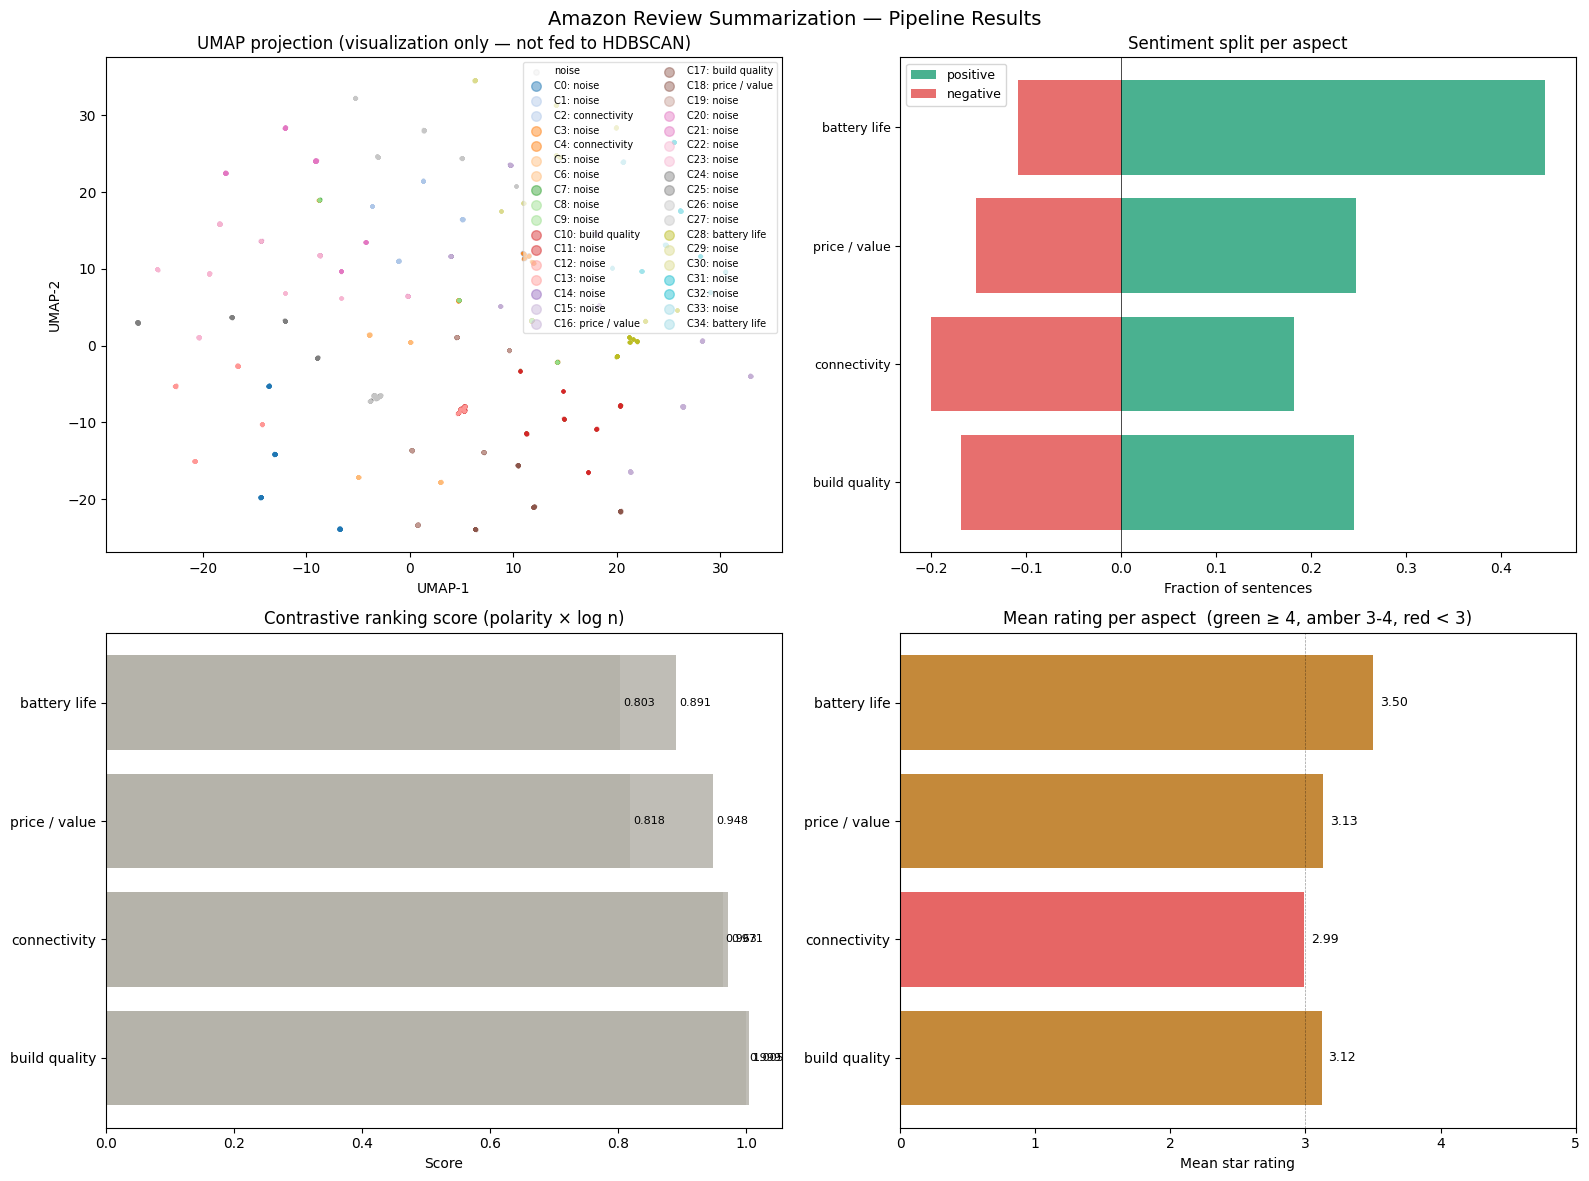

Saved: review_analysis.png


In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle("Amazon Review Summarization — Pipeline Results", fontsize=14, y=0.98)

# ── Plot 1: UMAP scatter (uses embeddings_2d from Stage 5) ──────────────────
ax = axes[0, 0]
unique_clusters = sorted(set(cluster_labels))
cmap  = plt.get_cmap("tab20", len(unique_clusters))
for idx, cid in enumerate(unique_clusters):
    mask  = cluster_labels == cid
    label = (f"C{cid}: {aspect_labels.get(cid, 'noise')[:14]}"
             if cid != -1 else "noise")
    color = "#cccccc" if cid == -1 else cmap(idx)
    alpha = 0.15 if cid == -1 else 0.45
    size  = 1   if cid == -1 else 3
    ax.scatter(embeddings_2d[mask, 0], embeddings_2d[mask, 1],
               s=size, c=[color], alpha=alpha, label=label)
ax.set_title("UMAP projection (visualization only — not fed to HDBSCAN)")
ax.legend(markerscale=4, fontsize=7, loc="upper right",
          framealpha=0.6, ncol=2)
ax.set_xlabel("UMAP-1"); ax.set_ylabel("UMAP-2")

# ── Plot 2: Per-aspect sentiment butterfly chart ────────────────────────────
ax2 = axes[0, 1]
labels_list = [a["aspect"]      for a in aspect_summaries]
pos_vals    = [a["pos_frac"]    for a in aspect_summaries]
neg_vals    = [-a["neg_frac"]   for a in aspect_summaries]
y = np.arange(len(labels_list))
ax2.barh(y, pos_vals, color="#1D9E75", alpha=0.8, label="positive")
ax2.barh(y, neg_vals, color="#E24B4A", alpha=0.8, label="negative")
ax2.set_yticks(y); ax2.set_yticklabels(labels_list, fontsize=9)
ax2.axvline(0, color="black", linewidth=0.5)
ax2.set_title("Sentiment split per aspect")
ax2.legend(fontsize=9)
ax2.set_xlabel("Fraction of sentences")

# ── Plot 3: Contrastive ranking score ──────────────────────────────────────
ax3 = axes[1, 0]
scores  = [t["score"]  for t in top_themes]
tlabels = [aspect_labels.get(t["cluster"], f"C{t['cluster']}") for t in top_themes]
colors  = ["#7F77DD" if t["polarity"] > 0.2 else "#B4B2A9" for t in top_themes]
bars = ax3.barh(tlabels, scores, color=colors, alpha=0.85)
ax3.set_title("Contrastive ranking score (polarity × log n)")
ax3.set_xlabel("Score")
for bar, score in zip(bars, scores):
    ax3.text(bar.get_width() + 0.005, bar.get_y() + bar.get_height()/2,
             f"{score:.3f}", va="center", fontsize=8)

# ── Plot 4: Mean rating per aspect ─────────────────────────────────────────
ax4 = axes[1, 1]
ratings_per_asp = [a["mean_rating"] for a in aspect_summaries]
bar_colors = ["#1D9E75" if r >= 4 else "#E24B4A" if r < 3 else "#BA7517"
              for r in ratings_per_asp]
ax4.barh(labels_list, ratings_per_asp, color=bar_colors, alpha=0.85)
ax4.axvline(3, color="black", linewidth=0.5, linestyle="--", alpha=0.4)
ax4.set_xlim(0, 5)
ax4.set_title("Mean rating per aspect  (green ≥ 4, amber 3-4, red < 3)")
ax4.set_xlabel("Mean star rating")
for i, r in enumerate(ratings_per_asp):
    ax4.text(r + 0.05, i, f"{r:.2f}", va="center", fontsize=9)

plt.tight_layout()
plt.savefig("review_analysis.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: review_analysis.png")


## Save outputs

In [ ]:
OUTPUT_JSON = "review_summary_local.json"

save_data = {
    "meta": {
        "model":        cfg["hf_id"],
        "model_type":   cfg["type"],
        "n_reviews":    len(reviews),
        "n_sentences":  len(sentences),
        "n_clusters":   n_clusters,
        "top_themes":   TOP_N_THEMES,
        "generated_at": datetime.now().isoformat(),
    },
    "verdict": {k: v for k, v in verdict.items() if k != "aspect_summaries"},
    "aspects": verdict["aspect_summaries"],
    "cluster_polarity": {str(k): v for k, v in polarity.items()},
}

with open(OUTPUT_JSON, "w", encoding="utf-8") as f:
    json.dump(save_data, f, indent=2, default=str)

print(f"Results saved to '{OUTPUT_JSON}'")
print(f"\nFinal summary:")
print(f"  Reviews processed   : {len(reviews):,}")
print(f"  Sentences embedded  : {len(sentences):,}")
print(f"  Clusters discovered : {n_clusters}")
print(f"  Aspects labelled    : {len(aspect_summaries)}")
print(f"  LLM calls made      : {len(aspect_summaries)}  (local, no API)")
print(f"  Overall sentiment   : {verdict['sentiment'].upper()}")
print(f"  Average rating      : {verdict['avg_rating']} / 5.0")


Results saved to 'review_summary_local.json'

Final summary:
  Reviews processed   : 2,000
  Sentences embedded  : 4,498
  Clusters discovered : 35
  Aspects labelled    : 4
  LLM calls made      : 4  (local, no API)
  Overall sentiment   : MIXED
  Average rating      : 3.19 / 5.0


In [ ]:
from google.colab import files
files.download("review_summary_local.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Eval Cell 1 — Install evaluation libraries
# rouge-score: Google's ROUGE implementation
# bert-score : semantic similarity via BERT embeddings
%pip install -q rouge-score bert-score

from rouge_score import rouge_scorer
import bert_score

print("Libraries ready.")

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.1/61.1 kB 3.9 MB/s eta 0:00:00
Libraries ready.


In [ ]:
# Eval Cell 2 — Quantitative metrics per aspect
#
# Reference = concatenation of the source sentences fed to the model.
# Hypothesis = the generated summary (positive + negative joined).
#
# ROUGE measures n-gram overlap (lexical).
# BERTScore measures semantic similarity (embedding-based).
# Faithfulness checks whether polarity direction matches cluster stats.

def build_reference(asp: str, sampled: list[dict]) -> str:
    """Use the source sentences as the pseudo-reference."""
    sents = [s["sent"] for s in sampled if s["aspect"] == asp]
    return " ".join(sents)

def rouge_scores(hypothesis: str, reference: str) -> dict:
    scorer = rouge_scorer.RougeScorer(
        ["rouge1", "rouge2", "rougeL"],
        use_stemmer=True
    )
    scores = scorer.score(reference, hypothesis)
    return {k: round(v.fmeasure, 3) for k, v in scores.items()}

def faithfulness_score(summary: dict, pol_stat: dict) -> float:
    """
    Check polarity alignment:
    If pos_frac > neg_frac the positive summary should be longer / more present.
    Returns a score 0-1: 1.0 = perfectly aligned, 0.0 = inverted.
    """
    pos_len = len((summary["positive"] or "").split())
    neg_len = len((summary["negative"] or "").split())
    total   = pos_len + neg_len + 1e-9
    gen_pos_frac = pos_len / total
    expected_pos = pol_stat["pos_frac"]
    # Similarity between generated pos fraction and actual pos fraction
    return round(1 - abs(gen_pos_frac - expected_pos), 3)

# Run ROUGE for all aspects first (fast)
eval_results = []
hypotheses, references = [], []

for asp_sum in aspect_summaries:
    asp       = asp_sum["aspect"]
    hyp       = " ".join(filter(None, [asp_sum["positive"], asp_sum["negative"]]))
    ref       = build_reference(asp, sampled)
    cid       = next(s["cluster"] for s in sampled if s["aspect"] == asp)
    pol_stat  = polarity.get(cid, {"pos_frac":0.5,"neg_frac":0.3})
    rg        = rouge_scores(hyp, ref)
    faith     = faithfulness_score(asp_sum, pol_stat)

    hypotheses.append(hyp)
    references.append(ref)
    eval_results.append({"aspect": asp, **rg,
                          "faithfulness": faith,
                          "hyp": hyp, "ref_len": len(ref.split())})

# BERTScore — one batched call for all aspects
print("Computing BERTScore (downloads model on first run)...")
P, R, F1 = bert_score.score(
    hypotheses, references,
    lang="en",
    model_type="distilbert-base-uncased",  # lightweight; change to roberta-large for best quality
    verbose=False,
)
for i, row in enumerate(eval_results):
    row["bert_f1"] = round(float(F1[i]), 3)

print("\\nMetrics per aspect:\\n")
print(f"{'Aspect':<22} {'R-1':<7} {'R-2':<7} {'R-L':<7} {'BERT-F1':<10} {'Faith'}")
print("-" * 65)
for r in eval_results:
    print(f"  {r['aspect']:<20}  {r['rouge1']:<7} {r['rouge2']:<7}"
          f" {r['rougeL']:<7} {r['bert_f1']:<10} {r['faithfulness']}")

avg = lambda k: round(sum(r[k] for r in eval_results) / len(eval_results), 3)
print(f"\\n  {'AVERAGE':<20}  {avg('rouge1'):<7} {avg('rouge2'):<7}"
      f" {avg('rougeL'):<7} {avg('bert_f1'):<10} {avg('faithfulness')}")

Computing BERTScore (downloads model on first run)...


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_transform.weight  | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


\nMetrics per aspect:\n
Aspect                 R-1     R-2     R-L     BERT-F1    Faith
-----------------------------------------------------------------
  build quality         0.116   0.071   0.116   0.744      0.695
  connectivity          0.0     0.0     0.0     0.63       0.432
  price / value         0.104   0.027   0.078   0.695      0.33
  battery life          0.167   0.143   0.167   0.785      0.589
\n  AVERAGE               0.097   0.06    0.09    0.714      0.511


In [ ]:
# Eval Cell 3 — Qualitative inspection
# Prints source sentences side-by-side with the generated summary
# for every aspect. This is the most important eval — read it.

SEPARATOR = "─" * 70

def print_qualitative(aspect_summaries, sampled, polarity, n_src_sentences=4):
    for asp_sum in aspect_summaries:
        asp      = asp_sum["aspect"]
        cid      = next(s["cluster"] for s in sampled if s["aspect"] == asp)
        pol      = polarity.get(cid, {})

        print(f"\\n{SEPARATOR}")
        print(f"  ASPECT : {asp.upper()}")
        print(f"  Stats  : ★{pol.get('mean_rating','?')}  "
              f"pos={pol.get('pos_frac',0):.0%}  "
              f"neg={pol.get('neg_frac',0):.0%}  "
              f"n={pol.get('n','?')} sentences")
        print(SEPARATOR)

        # Source sentences (top-weighted, pos then neg)
        src = [s for s in sampled if s["aspect"] == asp]
        src.sort(key=lambda x: -x["weight"])
        print(f"\\n  SOURCE SENTENCES (top {n_src_sentences} by weight):")
        for s in src[:n_src_sentences]:
            label = ("[POS]" if s["rating"] >= 4
                     else "[NEG]" if s["rating"] <= 2 else "[NEU]")
            print(f"    {label} ★{s['rating']:.0f}  {s['sent'][:100]}"
                  f"{'...' if len(s['sent']) > 100 else ''}")

        # Generated summary
        print(f"\\n  GENERATED SUMMARY:")
        print(f"    + {asp_sum['positive'] or '(empty)'}")
        print(f"    - {asp_sum['negative'] or '(empty)'}")

        # Quick self-assessment flags
        flags = []
        if not asp_sum["positive"]: flags.append("⚠ missing positive")
        if not asp_sum["negative"]: flags.append("⚠ missing negative")
        pos_words = asp_sum["positive"].lower().split() if asp_sum["positive"] else []
        neg_words = asp_sum["negative"].lower().split() if asp_sum["negative"] else []
        if len(set(pos_words) & set(neg_words)) > 5:
            flags.append("⚠ pos/neg very similar — possible repetition")
        if flags:
            print(f"\\n  FLAGS: {', '.join(flags)}")

    print(f"\\n{SEPARATOR}")

print_qualitative(aspect_summaries, sampled, polarity, n_src_sentences=4)

\n──────────────────────────────────────────────────────────────────────
  ASPECT : BUILD QUALITY
  Stats  : ★3.12  pos=24%  neg=17%  n=155 sentences
──────────────────────────────────────────────────────────────────────
\n  SOURCE SENTENCES (top 4 by weight):
    [NEU] ★2  Plastic feels premium but not durable.
    [NEU] ★2  Headband cracked after 5 months.
    [NEU] ★2  Plastic feels premium but not durable.
    [POS] ★4  Headband cracked after 5 months.
\n  GENERATED SUMMARY:
    + This headband has a low rating due to poor build quality.
    - 17% of customers found it cracked after 5 months.
\n──────────────────────────────────────────────────────────────────────
  ASPECT : CONNECTIVITY
  Stats  : ★2.99  pos=18%  neg=20%  n=165 sentences
──────────────────────────────────────────────────────────────────────
\n  SOURCE SENTENCES (top 4 by weight):
    [NEG] ★2  Bluetooth drops every few minutes.
    [POS] ★4  Bluetooth drops every few minutes.
    [NEU] ★2  Bluetooth drops every fe

In [ ]:
# Eval Cell 4 — Summary scorecard + low-performer diagnosis

def print_scorecard(eval_results: list[dict]) -> None:
    print("\\n===== OVERALL SCORECARD =====")
    avg = lambda k: round(sum(r[k] for r in eval_results)/len(eval_results),3)
    print(f"  ROUGE-1      : {avg('rouge1')}  (lexical overlap — 0.3+ is reasonable)")
    print(f"  ROUGE-2      : {avg('rouge2')}  (bigrams — lower is normal for abstractive)")
    print(f"  ROUGE-L      : {avg('rougeL')}  (longest common subsequence)")
    print(f"  BERTScore F1 : {avg('bert_f1')}  (semantic — 0.80+ is good)")
    print(f"  Faithfulness : {avg('faithfulness')}  (polarity alignment — 0.75+ is good)")

    print("\\n===== INTERPRETATION =====")
    bert_avg = avg("bert_f1")
    rouge_avg = avg("rouge1")
    faith_avg = avg("faithfulness")

    if bert_avg >= 0.82:
        print("  BERTScore: GOOD — summaries are semantically faithful to sources.")
    elif bert_avg >= 0.75:
        print("  BERTScore: OK — some semantic drift; try flan-t5-large or bart-large-cnn.")
    else:
        print("  BERTScore: POOR — model is hallucinating or ignoring input.")

    if rouge_avg < 0.2:
        print("  ROUGE-1: LOW — model is paraphrasing heavily (may be fine) or off-topic.")
    elif rouge_avg > 0.6:
        print("  ROUGE-1: HIGH — model may be copying source verbatim (extractive, not abstractive).")
    else:
        print("  ROUGE-1: REASONABLE — good balance of paraphrasing and coverage.")

    if faith_avg < 0.70:
        print("  Faithfulness: LOW — summaries may misrepresent sentiment direction.")
        print("    → Try adding explicit pos/neg word counts to the prompt.")

    print("\\n===== WORST PERFORMING ASPECTS =====")
    worst = sorted(eval_results, key=lambda x: x["bert_f1"])[:2]
    for w in worst:
        print(f"  {w['aspect']:<22} BERT={w['bert_f1']}  faith={w['faithfulness']}")
        if w["bert_f1"] < 0.80:
            print("    → Likely cause: few source sentences for this aspect.")
            print(f"    → Source reference length: {w['ref_len']} words")
            print("    → Fix: increase SENTENCES_PER_BUCKET or lower HDBSCAN_MIN_SIZE.")

print_scorecard(eval_results)

\n===== OVERALL SCORECARD =====
  ROUGE-1      : 0.097  (lexical overlap — 0.3+ is reasonable)
  ROUGE-2      : 0.06  (bigrams — lower is normal for abstractive)
  ROUGE-L      : 0.09  (longest common subsequence)
  BERTScore F1 : 0.714  (semantic — 0.80+ is good)
  Faithfulness : 0.511  (polarity alignment — 0.75+ is good)
\n===== INTERPRETATION =====
  BERTScore: POOR — model is hallucinating or ignoring input.
  ROUGE-1: LOW — model is paraphrasing heavily (may be fine) or off-topic.
  Faithfulness: LOW — summaries may misrepresent sentiment direction.
    → Try adding explicit pos/neg word counts to the prompt.
\n===== WORST PERFORMING ASPECTS =====
  connectivity           BERT=0.63  faith=0.432
    → Likely cause: few source sentences for this aspect.
    → Source reference length: 66 words
    → Fix: increase SENTENCES_PER_BUCKET or lower HDBSCAN_MIN_SIZE.
  price / value          BERT=0.695  faith=0.33
    → Likely cause: few source sentences for this aspect.
    → Source refer

In [ ]:
import os
import requests
import numpy as np
import pandas as pd
from tqdm import tqdm

import nltk
from nltk.tokenize import sent_tokenize

from sentence_transformers import SentenceTransformer

import hdbscan
import umap

from sklearn.metrics.pairwise import cosine_similarity
from collections import defaultdict

import matplotlib.pyplot as plt
import seaborn as sns

from scipy.cluster.hierarchy import linkage, dendrogram

#from keybert import KeyBERT

In [ ]:
#url = "https://huggingface.co/datasets/McAuley-Lab/Amazon-Reviews-2023/resolve/main/raw/review_categories/All_Beauty.jsonl"
url = "https://huggingface.co/datasets/McAuley-Lab/Amazon-Reviews-2023/resolve/main/raw/review_categories/Clothing_Shoes_and_Jewelry.jsonl"
#filename = "All_Beauty.jsonl"
filename = "Clothing_Shoes_and_Jewelry.jsonl"

if not os.path.exists(filename):
    print("Downloading dataset...")
    r = requests.get(url, stream=True)
    r.raise_for_status()
    with open(filename, "wb") as f:
        for chunk in r.iter_content(chunk_size=4*1024*1024):
            f.write(chunk)
    print("Download complete")
else:
    print("Dataset already exists")

df = pd.read_json(filename, lines=True)
print("Total reviews:", len(df))
df.head()

Download complete
